# 01b - Khám phá dữ liệu: Biến phân loại, dữ liệu khuyết và mối quan hệ

Các quy ước từ mục **2.1 Overview** được áp dụng đồng bộ tiếp nối `01a_collection_overview_numeric.ipynb`.
- Tạo `release_year` (`int32`) từ `track_album_release_date` và `duration_min` từ `duration_ms`.
- Đổi kiểu `category` cho `playlist_genre`, `playlist_subgenre`, `key`, `mode`.
- Tách 2 góc nhìn để tránh méo thống kê do 4.477 dòng lặp `track_id`:
  - `df` (**32.833 dòng** – cấp *bài hát × playlist × subgenre*): dùng khi khảo sát các cột thuộc playlist và giao thoa thể loại.
  - `df_tracks` (**28.356 dòng** – cấp *bài hát độc nhất*): dùng khi khảo sát các thuộc tính cấp bài hát (`key`, `mode`, `track_artist`, tương quan biến số, quan hệ `release_year` – `track_popularity`).

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:.2f}'.format)

DATA = '../data/raw/spotify_songs.csv'
df = pd.read_csv(DATA)
# TODO: thay bằng hàm load/clean dùng chung trong src/ sau khi chốt kế hoạch tiền xử lý ở mục 2.6

# Đồng bộ các biến dẫn xuất và kiểu dữ liệu
df['release_year'] = pd.to_datetime(df['track_album_release_date'], format='mixed').dt.year.astype('int32')
df['duration_min'] = df['duration_ms'] / 60000

cat_cols = ['playlist_genre', 'playlist_subgenre', 'key', 'mode']
df[cat_cols] = df[cat_cols].astype('category')

# Bảng các bài hát độc nhất (1 dòng / track_id)
df_tracks = df.drop_duplicates(subset='track_id').copy()

print(f'df (bảng các bài hát được lấy từ playlist): {df.shape}')
print(f'df_tracks (bảng các bài hát độc nhất): {df_tracks.shape}')
print('\nKiểu dữ liệu các cột đã chuyển đổi:')
print(df[cat_cols + ['release_year', 'duration_min']].dtypes)

df (bảng các bài hát được lấy từ playlist): (32833, 25)
df_tracks (bảng các bài hát độc nhất): (28356, 25)

Kiểu dữ liệu các cột đã chuyển đổi:
playlist_genre       category
playlist_subgenre    category
key                  category
mode                 category
release_year            int32
duration_min          float64
dtype: object


## 2.3 Categorical columns

Tập trung khảo sát sâu 4 cột phân loại chính (`playlist_genre`, `playlist_subgenre`, `key`, `mode`) và tóm tắt ngắn gọn 2 cột có độ phân mảnh cao (`track_artist`, `playlist_id`).

### Phân bố & độ cân bằng của `playlist_genre` và `playlist_subgenre`

In [33]:
genre_summary = (
    df.groupby('playlist_genre', observed=True)
    .agg(rows=('track_id', 'size'), unique_tracks=('track_id', 'nunique'))
    .assign(
        row_pct=lambda x: x['rows'] / len(df) * 100,
        dup_in_genre_pct=lambda x: (1 - x['unique_tracks'] / x['rows']) * 100,
    )
    .sort_values('rows', ascending=False)
)
display(genre_summary)

subgenre_summary = (
    df.groupby(['playlist_genre', 'playlist_subgenre'], observed=True)
    .agg(rows=('track_id', 'size'), unique_tracks=('track_id', 'nunique'))
    .reset_index()
    .sort_values('rows', ascending=True)
)
print('Top 5 subgenre ít bài nhất và top 5 subgenre nhiều bài nhất')
display(pd.concat([subgenre_summary.head(5), subgenre_summary.tail(5)])) 
print('Tổng quan phân bố số dòng trên toàn bộ 24 subgenre')   
display(subgenre_summary['rows'].describe().to_frame().T)
print('Số subgenre có trùng track_id nội bộ:', (subgenre_summary['rows'] != subgenre_summary['unique_tracks']).sum())

,rows,unique_tracks,row_pct,dup_in_genre_pct
playlist_genre,,,,
edm,6043,5537,18.41,8.37
rap,5746,5486,17.50,4.52
pop,5507,5132,16.77,6.81
r&b,5431,5138,16.54,5.39
latin,5155,4641,15.70,9.97
rock,4951,4451,15.08,10.10


Top 5 subgenre ít bài nhất và top 5 subgenre nhiều bài nhất


,playlist_genre,playlist_subgenre,rows,unique_tracks
6,latin,reggaeton,949,949
20,rock,album rock,1065,1065
23,rock,permanent wave,1105,1105
11,pop,post-teen pop,1129,1129
14,r&b,new jack swing,1133,1133
13,r&b,neo soul,1637,1637
4,latin,latin hip hop,1656,1656
10,pop,indie poptimism,1672,1672
18,rap,southern hip hop,1675,1675
3,edm,progressive electro house,1809,1809


Tổng quan phân bố số dòng trên toàn bộ 24 subgenre


,count,mean,std,min,25%,50%,75%,max
rows,24.00,1368.04,221.39,949.00,1243.50,1310.00,1512.50,1809.00


Số subgenre có trùng track_id nội bộ: 0


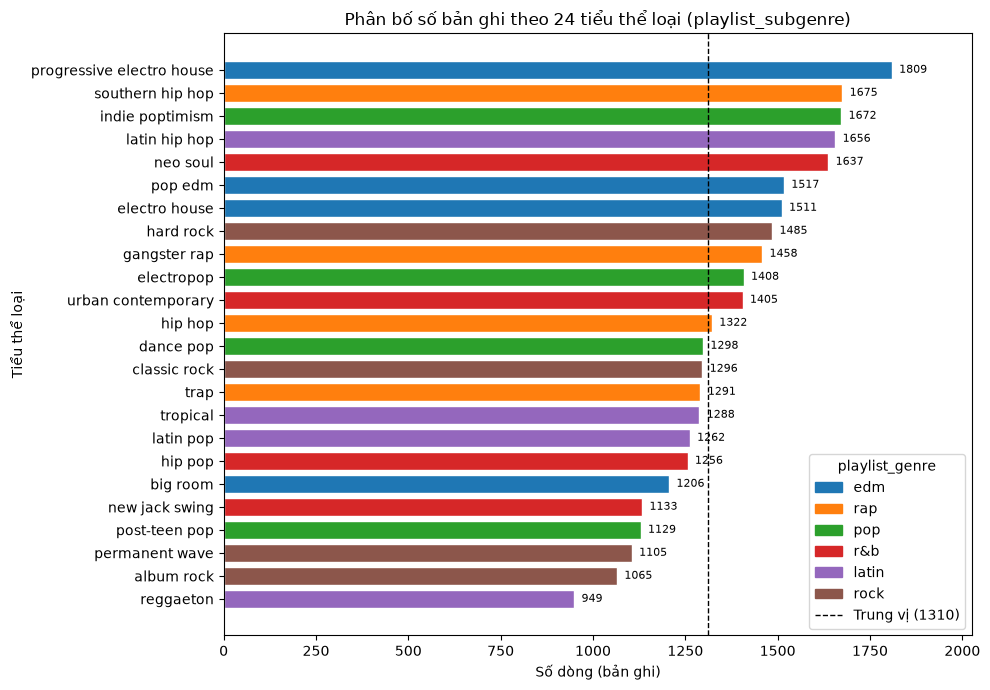

In [34]:
genres = genre_summary.index.tolist()
cmap = plt.get_cmap('tab10')
genre_colors = {g: cmap(i) for i, g in enumerate(genres)}

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    subgenre_summary['playlist_subgenre'].astype(str),
    subgenre_summary['rows'],
    color=[genre_colors[g] for g in subgenre_summary['playlist_genre']],
    edgecolor='white',
)
ax.axvline(subgenre_summary['rows'].median(), color='black', linestyle='--', linewidth=1, label=f"Trung vị ({subgenre_summary['rows'].median():.0f})")
for bar in bars:
    w = bar.get_width()
    ax.text(w + 20, bar.get_y() + bar.get_height() / 2, f'{int(w)}', va='center', fontsize=8)

handles = [plt.Rectangle((0, 0), 1, 1, color=genre_colors[g]) for g in genres]
handles.append(plt.Line2D([0], [0], color='black', linestyle='--', linewidth=1))
ax.legend(handles, genres + [f"Trung vị ({subgenre_summary['rows'].median():.0f})"], title='playlist_genre', loc='lower right')
ax.set_title('Phân bố số bản ghi theo 24 tiểu thể loại (playlist_subgenre)')
ax.set_xlabel('Số dòng (bản ghi)')
ax.set_ylabel('Tiểu thể loại')
ax.set_xlim(0, subgenre_summary['rows'].max() * 1.12)
plt.tight_layout()
plt.show()

### Phân bố key và mode (tính trên những bài độc nhất)

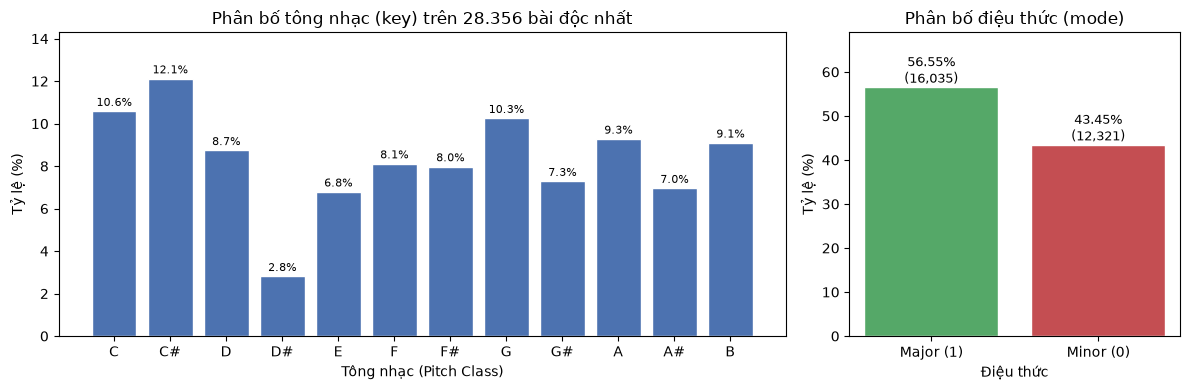

In [35]:
key_map = {0: 'C', 1: 'C#', 2: 'D', 3: 'D#', 4: 'E', 5: 'F', 6: 'F#', 7: 'G', 8: 'G#', 9: 'A', 10: 'A#', 11: 'B'}
mode_map = {0: 'Minor (0)', 1: 'Major (1)'}

key_counts = df_tracks['key'].astype(int).map(key_map).value_counts().reindex(key_map.values())
mode_counts = df_tracks['mode'].astype(int).map(mode_map).value_counts().reindex(['Major (1)', 'Minor (0)'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [2.2, 1]})

# Key
key_pct = key_counts / len(df_tracks) * 100
axes[0].bar(key_counts.index, key_pct, color='#4C72B0', edgecolor='white')
for i, (k, pct) in enumerate(key_pct.items()):
    axes[0].text(i, pct + 0.25, f'{pct:.1f}%', ha='center', fontsize=8)
axes[0].set_title('Phân bố tông nhạc (key) trên 28.356 bài độc nhất')
axes[0].set_xlabel('Tông nhạc (Pitch Class)')
axes[0].set_ylabel('Tỷ lệ (%)')
axes[0].set_ylim(0, key_pct.max() * 1.18)

# Mode
mode_pct = mode_counts / len(df_tracks) * 100
axes[1].bar(mode_counts.index, mode_pct, color=['#55A868', '#C44E52'], edgecolor='white')
for i, (m, pct) in enumerate(mode_pct.items()):
    axes[1].text(i, pct + 1.0, f'{pct:.2f}%\n({mode_counts[m]:,})', ha='center', fontsize=9)
axes[1].set_title('Phân bố điệu thức (mode)')
axes[1].set_xlabel('Điệu thức')
axes[1].set_ylabel('Tỷ lệ (%)')
axes[1].set_ylim(0, mode_pct.max() * 1.22)

plt.tight_layout()
plt.show()

### Kiểm tra tính nhất quán nhãn & giao thoa đa thể loại

In [36]:
# 1. Kiểm tra lỗi hoa/thường và khoảng trắng thừa
for col in ['playlist_genre', 'playlist_subgenre', 'track_artist']:
    s = df[col].dropna().astype(str)
    n_raw = s.nunique()
    n_norm = s.str.strip().str.lower().nunique()
    print(f'{col:20s}: nunique gốc = {n_raw:5d} | sau chuẩn hóa = {n_norm:5d} | chênh lệch = {n_raw - n_norm}')

# In các trường hợp track_artist chỉ khác hoa/thường
artists_uniq = pd.DataFrame({'raw': df['track_artist'].dropna().unique()})
artists_uniq['norm'] = artists_uniq['raw'].str.strip().str.lower()
case_variants = artists_uniq[artists_uniq.duplicated('norm', keep=False)].sort_values('norm')
print('\nCác tên track_artist chỉ khác nhau về viết hoa/thường:')
display(case_variants.reset_index(drop=True))

# 2. Top tổ hợp thể loại ở 1.687 bài xuất hiện từ >= 2 thể loại
track_genres = df.groupby('track_id')['playlist_genre'].apply(lambda x: tuple(sorted(set(x))))
multi_genre_combos = track_genres[track_genres.apply(len) >= 2].value_counts()
print(f'\nTop 10 tổ hợp thể loại giao thoa (trên tổng {len(track_genres[track_genres.apply(len) >= 2]):,} bài đa thể loại):')
display(multi_genre_combos.head(10).to_frame(name='so_bai'))

playlist_genre      : nunique gốc =     6 | sau chuẩn hóa =     6 | chênh lệch = 0
playlist_subgenre   : nunique gốc =    24 | sau chuẩn hóa =    24 | chênh lệch = 0
track_artist        : nunique gốc = 10692 | sau chuẩn hóa = 10685 | chênh lệch = 7

Các tên track_artist chỉ khác nhau về viết hoa/thường:


,raw,norm
0,audrey,audrey
1,Audrey,audrey
2,CREAM,cream
3,Cream,cream
4,Davi,davi
5,DAVI,davi
6,gizmo,gizmo
7,Gizmo,gizmo
8,Mase,mase
9,MASE,mase



Top 10 tổ hợp thể loại giao thoa (trên tổng 1,687 bài đa thể loại):


,so_bai
playlist_genre,
"(edm, pop)",274
"(pop, r&b)",217
"(latin, pop)",180
"(latin, rap)",148
"(r&b, rap)",147
"(pop, rock)",107
"(edm, latin)",93
"(edm, rap)",61
"(edm, r&b)",55


### Tóm tắt các cột cardinality cao & kiểm tra nhóm hiếm (`track_artist`, `playlist_id`)

In [37]:
artist_counts = df_tracks['track_artist'].value_counts()
print('Top 10 nghệ sĩ có nhiều bài hát độc nhất nhất:')
display(artist_counts.head(10).to_frame(name='unique_tracks'))

for k in [1, 2, 5]:
    cnt = (artist_counts <= k).sum()
    print(f'Nghệ sĩ có <= {k} bài: {cnt:,} / {len(artist_counts):,} ({cnt / len(artist_counts) * 100:.2f}%)')

print('\nTóm tắt số bản ghi trên mỗi playlist_id (471 playlist):')
display(df['playlist_id'].value_counts().describe().to_frame(name='rows_per_playlist').T)

Top 10 nghệ sĩ có nhiều bài hát độc nhất nhất:


,unique_tracks
track_artist,
Queen,130
Martin Garrix,87
Don Omar,84
David Guetta,81
Dimitri Vegas & Like Mike,68
Hardwell,68
Drake,68
The Chainsmokers,66
Logic,65


Nghệ sĩ có <= 1 bài: 6,496 / 10,692 (60.76%)
Nghệ sĩ có <= 2 bài: 8,206 / 10,692 (76.75%)
Nghệ sĩ có <= 5 bài: 9,698 / 10,692 (90.70%)

Tóm tắt số bản ghi trên mỗi playlist_id (471 playlist):


,count,mean,std,min,25%,50%,75%,max
rows_per_playlist,471.00,69.71,31.17,1.00,47.00,75.00,95.50,247.00


### Kết luận mục 2.3
- **Độ cân bằng:**
  - 6 `playlist_genre` khá cân bằng (từ `rock` 15,08% đến `edm` 18,41%). Tỷ lệ lặp `track_id` nội bộ cao nhất ở `rock` (10,10%) và `latin` (9,97%), thấp nhất ở `rap` (4,52%).
  - 24 `playlist_subgenre` cũng tương đối đồng đều (949–1.809 dòng; trung vị 1.310), **không có tiểu thể loại nào quá hiếm cần gom nhóm**. Đáng chú ý, trong cùng một `playlist_subgenre` không hề có bài hát trùng lặp (`rows == unique_tracks` ở cả 24 nhóm) — nghĩa là mọi trường hợp lặp `track_id` đều phát sinh từ việc bài hát nằm ở **khác tiểu thể loại**.
  - Trên 28.356 bài độc nhất, `mode` hơi nghiêng về điệu Trưởng (`Major` 56,55% vs `Minor` 43,45%); `key` phổ biến nhất là `C#` (12,12%) và `C` (10,58%), trong khi `D#` hiếm rõ rệt (chỉ 2,81%).
- **Tính nhất quán nhãn & giao thoa thể loại:**
  - `playlist_genre` và `playlist_subgenre` hoàn toàn sạch, không có lỗi chính tả hay khoảng trắng thừa.
  - `track_artist` có 7 cặp khác nhau về viết hoa/thường (`audrey`/`Audrey`, `CREAM`/`Cream`, `TOBi`/`Tobi`, …) — có thể là nghệ sĩ trùng tên trên Spotify hoặc biến thể hiển thị; cần lưu ý nếu ghép dữ liệu ngoài theo tên nghệ sĩ.
  - Trong 1.687 bài đa thể loại, `pop` là trung tâm giao thoa lớn nhất: `(edm, pop)` (274 bài), `(pop, r&b)` (217 bài), `(latin, pop)` (180 bài), theo sau là `(latin, rap)` (148) và `(r&b, rap)` (147). Đây là bằng chứng rõ cho *label noise* khi dùng nhãn playlist thay cho thể loại gốc.
- **Nhóm hiếm & hệ quả cho tiền xử lý:**
  - Giữ nguyên toàn bộ nhóm `playlist_genre`, `playlist_subgenre`, `key`, `mode`, không cần gom thành nhóm `Other`.
  - `track_artist` có đuôi dài rất nặng (**60,76%** nghệ sĩ chỉ có 1 bài, **90,70%** có ≤ 5 bài), nên không thể one-hot encode trực tiếp cho mô hình ML (nếu dùng cần gom nhóm `Other`/mã hóa tần suất, hoặc dùng `track_artist` làm khóa chia nhóm `GroupKFold` để tránh rò rỉ dữ liệu theo nghệ sĩ).

## 2.4 Missing data

Kiểm tra đồng thời **dữ liệu `NaN`** và **dữ liệu ngày tháng bị mất** hoặc **có giá trị `0` bất thường**.

### Dữ liệu `NaN`

In [38]:
na_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct (%)': (df.isna().mean() * 100).round(4),
})
print('Các cột có giá trị NaN:')
display(na_summary[na_summary['missing_count'] > 0])

na_rows = df[df.isna().any(axis=1)]
print(f"Tổng số dòng chứa ít nhất 1 NaN: {len(na_rows)} (gồm {na_rows['track_id'].nunique()} track_id độc nhất)")
display(na_rows[['track_id', 'track_name', 'track_artist', 'track_album_name', 'track_popularity', 'playlist_genre', 'release_year']])

Các cột có giá trị NaN:


,missing_count,missing_pct (%)
track_name,5,0.02
track_artist,5,0.02
track_album_name,5,0.02


Tổng số dòng chứa ít nhất 1 NaN: 5 (gồm 4 track_id độc nhất)


,track_id,track_name,track_artist,track_album_name,track_popularity,playlist_genre,release_year
8151,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,NaN,0,rap,2012
9282,5cjecvX0CmC9gK0Laf5EMQ,NaN,NaN,NaN,0,rap,2017
9283,5TTzhRSWQS4Yu8xTgAuq6D,NaN,NaN,NaN,0,rap,2017
19568,3VKFip3OdAvv4OfNTgFWeQ,NaN,NaN,NaN,0,latin,2012
19811,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,NaN,0,latin,2012


### Dữ liệu bị mất ở ngày phát hành (`YYYY` / `YYYY-MM` thiếu ngày, tháng)

Tỷ lệ định dạng ngày phát hành (%) theo thập kỷ (trên df_tracks):


track_album_release_date,YYYY-MM-DD,YYYY-MM,YYYY
release_year,,,
1950s,66.67,33.33,0.00
1960s,74.24,3.79,21.97
1970s,67.05,2.04,30.91
1980s,72.94,0.28,26.79
1990s,80.73,0.00,19.27
2000s,87.23,0.00,12.77
2010s,98.96,0.00,1.04
2020s,100.00,0.00,0.00


Tỷ lệ định dạng ngày phát hành (%) theo thể loại (trên df):


track_album_release_date,YYYY-MM-DD,YYYY-MM,YYYY
playlist_genre,,,
edm,98.78,0.00,1.22
latin,96.28,0.00,3.72
pop,96.30,0.04,3.67
r&b,93.79,0.07,6.13
rap,95.21,0.02,4.77
rock,83.76,0.48,15.75


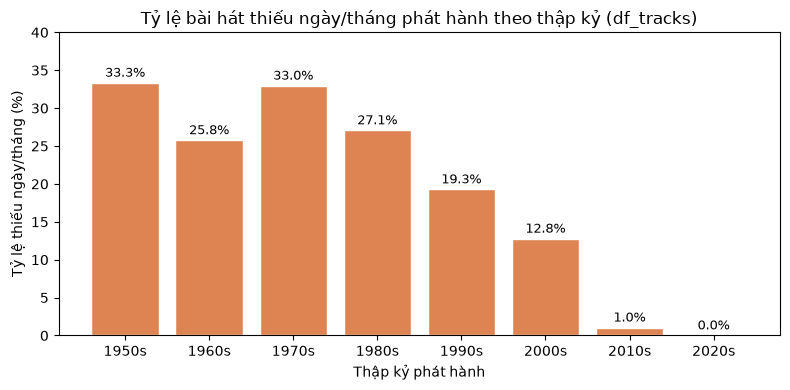

In [39]:
date_fmt_map = {10: 'YYYY-MM-DD', 7: 'YYYY-MM', 4: 'YYYY'}
date_fmt_tracks = df_tracks['track_album_release_date'].str.len().map(date_fmt_map)
decade_tracks = (df_tracks['release_year'] // 10 * 10).astype(str) + 's'

ct_decade = pd.crosstab(decade_tracks, date_fmt_tracks, normalize='index') * 100
ct_decade = ct_decade.reindex(columns=['YYYY-MM-DD', 'YYYY-MM', 'YYYY'], fill_value=0)
print('Tỷ lệ định dạng ngày phát hành (%) theo thập kỷ (trên df_tracks):')
display(ct_decade)

ct_genre_date = pd.crosstab(
    df['playlist_genre'],
    df['track_album_release_date'].str.len().map(date_fmt_map),
    normalize='index',
) * 100
print('Tỷ lệ định dạng ngày phát hành (%) theo thể loại (trên df):')
display(ct_genre_date.reindex(columns=['YYYY-MM-DD', 'YYYY-MM', 'YYYY'], fill_value=0))

# Biểu đồ tỷ lệ thiếu ngày/tháng theo thập kỷ
missing_md_pct = ct_decade['YYYY'] + ct_decade['YYYY-MM']
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(missing_md_pct.index, missing_md_pct.values, color='#DD8452', edgecolor='white')
for bar, val in zip(bars, missing_md_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.8, f'{val:.1f}%', ha='center', fontsize=9)
ax.set_title('Tỷ lệ bài hát thiếu ngày/tháng phát hành theo thập kỷ (df_tracks)')
ax.set_xlabel('Thập kỷ phát hành')
ax.set_ylabel('Tỷ lệ thiếu ngày/tháng (%)')
ax.set_ylim(0, missing_md_pct.max() * 1.2)
plt.tight_layout()
plt.show()

### Kiểm tra giá trị `0` / bất thường đáng ngờ (trên `df_tracks`)

In [40]:
anomaly_checks = {
    'track_popularity == 0': df_tracks['track_popularity'] == 0,
    'tempo == 0': df_tracks['tempo'] == 0,
    'danceability == 0': df_tracks['danceability'] == 0,
    'energy == 0': df_tracks['energy'] == 0,
    'loudness > 0 dB': df_tracks['loudness'] > 0,
    'duration_min < 0.5': df_tracks['duration_min'] < 0.5,
}
anomaly_summary = pd.DataFrame({
    'so_bai': {k: int(v.sum()) for k, v in anomaly_checks.items()},
    'ty_le (%)': {k: round(v.mean() * 100, 3) for k, v in anomaly_checks.items()},
})
display(anomaly_summary)

print('Bài hát có tempo == 0 hoặc danceability == 0:')
display(df_tracks[(df_tracks['tempo'] == 0) | (df_tracks['danceability'] == 0)][[
    'track_id', 'track_name', 'track_artist', 'track_popularity', 'tempo', 'danceability', 'energy', 'duration_min', 'playlist_genre'
]])

print('Tỷ lệ track_popularity == 0 (%) theo thể loại (trên df):')
display((df.groupby('playlist_genre', observed=True)['track_popularity'].apply(lambda s: (s == 0).mean() * 100)).to_frame(name='pop_zero_pct (%)').sort_values('pop_zero_pct (%)', ascending=False))

,so_bai,ty_le (%)
track_popularity == 0,2620,9.24
tempo == 0,1,0.00
danceability == 0,1,0.00
energy == 0,0,0.00
loudness > 0 dB,6,0.02
duration_min < 0.5,2,0.01


Bài hát có tempo == 0 hoặc danceability == 0:


,track_id,track_name,track_artist,track_popularity,tempo,danceability,energy,duration_min,playlist_genre
11363,51w6nRCU68klqNfYaaVP2j,"Hi, How're You Doin'?",DREAMS COME TRUE,0,0.00,0.00,0.32,0.07,rock


Tỷ lệ track_popularity == 0 (%) theo thể loại (trên df):


,pop_zero_pct (%)
playlist_genre,
edm,11.90
r&b,9.04
rock,7.86
rap,7.59
latin,6.89
pop,5.68


### Kết luận mục 2.4 & Kế hoạch xử lý dữ liệu khuyết
- **Dữ liệu `NaN`:** Chỉ có 3 cột (`track_name`, `track_artist`, `track_album_name`) bị khuyết và **khuyết đồng thời trên cùng 5 dòng** (0,015%, ứng với 4 `track_id` độc nhất vì 1 bài xuất hiện ở cả `rap` và `latin`). 12 đặc trưng âm thanh và `track_popularity` đều đầy đủ.
  - *Nguyên nhân:* Metadata bị gỡ/hạn chế bản quyền từ Spotify API tại thời điểm thu thập.
  - *Cách xử lý:* **Drop 5 dòng này** khi làm sạch cho các phân tích cần tên bài/nghệ sĩ hoặc ghép dữ liệu ngoài (tổn thất không đáng kể < 0,02%).
- **Dữ liệu bị mất ngày/tháng phát hành:**
  - 5,84% bài độc nhất chỉ có `YYYY` và 0,09% chỉ có `YYYY-MM`, tập trung rất mạnh ở nhạc cũ: thập niên 1970 (30,91%), 1980 (26,79%), 1960 (21,97%), giảm xuống chỉ còn 1,04% ở thập niên 2010 và 0% ở 2020. Do `rock` có nhiều nhạc cũ nên tỷ lệ thiếu ngày/tháng ở `rock` lên tới **16,23%** (so với 1,22% ở `edm`).
  - *Cách xử lý:* Không nội suy ngày/tháng (vì sẽ gây sai lệch hệ thống); chỉ dùng `release_year`.
- **Các giá trị `0` / bất thường:**
  - `tempo == 0` và `danceability == 0`: chỉ **1 bài duy nhất** (`Hi, How're You Doin'?` — dài 0,07 phút ≈ 4 giây, là đoạn thoại mở đầu nên API không ước lượng được nhịp) → **loại bỏ** khi phân tích đặc trưng âm thanh hoặc huấn luyện ML.
  - `loudness > 0 dB`: chỉ **6 bài** (0,02%), đều có `energy` rất cao (0,86–1,00) → là bản thu âm lượng lớn thật (digital clipping), **giữ nguyên**.
  - `track_popularity == 0`: chiếm **2.620 bài (9,24%)**, cao nhất ở `edm` (11,90%) và thấp nhất ở `pop` (5,68%), có năm phát hành trung vị cũ hơn (2012 vs 2016) → phản ánh hỗn hợp bài ít lượt nghe và bản phát hành cũ/bị thay thế trên Spotify. **Không xóa mặc định**, nhưng sẽ tách làm kiểm tra độ nhạy (**robustness check – D6**) trong các phân tích về `track_popularity`.

## 2.5 Relationships

Khám phá mối quan hệ giữa các biến số, kiểm chứng giả thuyết *Recency Bias*, so sánh hồ sơ âm thanh theo thể loại, và phát hiện các biến nhiễu để dẫn sang bước đặt câu hỏi.

### Tương quan giữa các biến số (Spearman trên `df_tracks`)

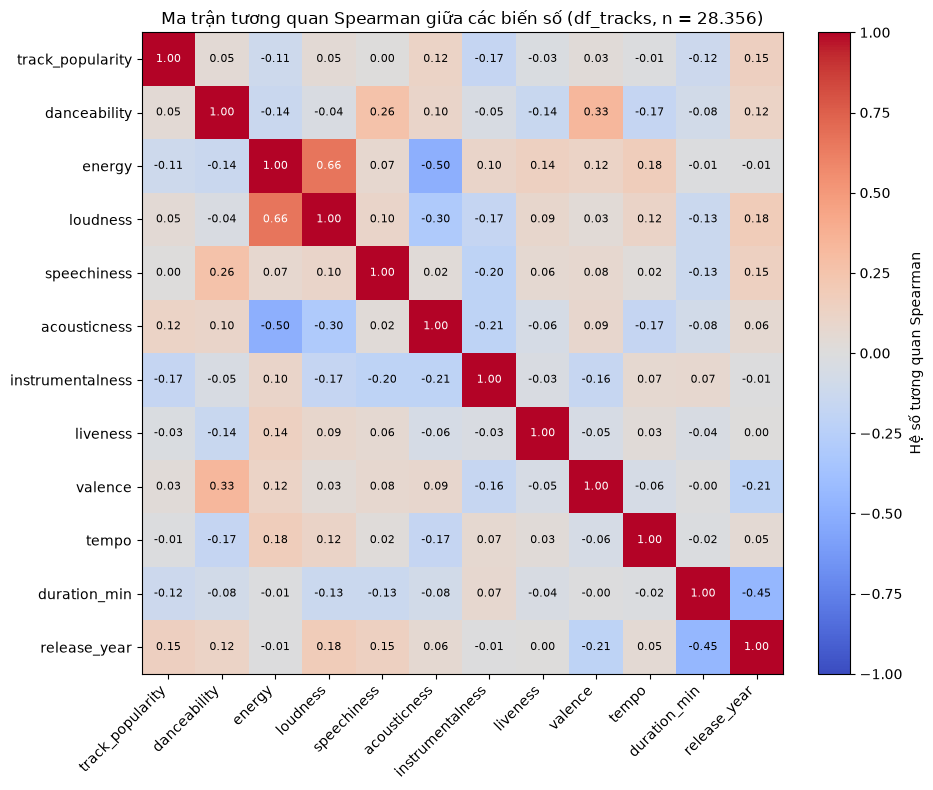

Tương quan Spearman với track_popularity:


,spearman_r
instrumentalness,-0.17
duration_min,-0.12
energy,-0.11
liveness,-0.03
tempo,-0.01
speechiness,0.00
valence,0.03
loudness,0.05
danceability,0.05
acousticness,0.12


In [41]:
num_cols = [
    'track_popularity', 'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'duration_min', 'release_year'
]
# Dùng Spearman vì nhiều cột lệch mạnh
corr_spearman = df_tracks[num_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_spearman.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='right')
ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        val = corr_spearman.iloc[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(val) > 0.5 else 'black')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Hệ số tương quan Spearman')
ax.set_title('Ma trận tương quan Spearman giữa các biến số (df_tracks, n = 28.356)')
plt.tight_layout()
plt.show()

print('Tương quan Spearman với track_popularity:')
display(corr_spearman['track_popularity'].drop('track_popularity').sort_values().to_frame(name='spearman_r'))

### Kiểm chứng *Recency Bias* và xu hướng âm nhạc theo thập kỷ (trên `df_tracks`)

,so_bai,pop_median,pop_mean,pop_zero_pct,loudness_med,duration_med
release_year,,,,,,
1950s,3,59.00,44.33,0.00,-5.02,2.44
1960s,132,56.50,46.45,4.55,-9.45,3.16
1970s,783,50.00,44.26,5.75,-9.34,4.04
1980s,1090,47.00,42.19,4.77,-9.25,4.32
1990s,2081,42.00,37.97,9.37,-8.21,4.36
2000s,3807,34.00,31.93,19.60,-6.24,3.99
2010s,19834,43.00,40.38,7.94,-5.88,3.46
2020s,626,43.00,42.78,0.16,-6.41,3.15


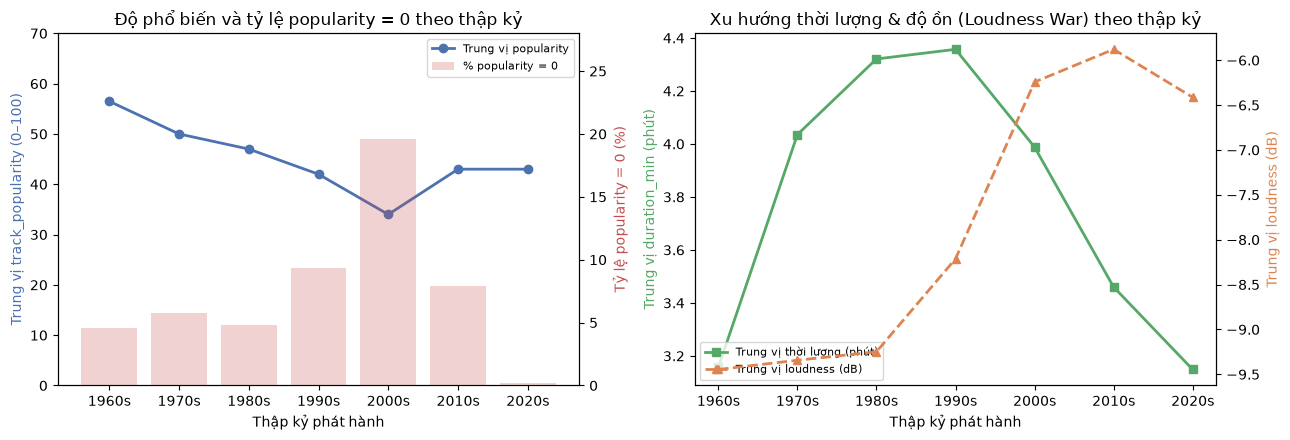

In [42]:
decade_series = (df_tracks['release_year'] // 10 * 10).astype(str) + 's'
decade_stats = df_tracks.groupby(decade_series).agg(
    so_bai=('track_id', 'size'),
    pop_median=('track_popularity', 'median'),
    pop_mean=('track_popularity', 'mean'),
    pop_zero_pct=('track_popularity', lambda s: (s == 0).mean() * 100),
    loudness_med=('loudness', 'median'),
    duration_med=('duration_min', 'median'),
)
display(decade_stats)

# Vì 1950s chỉ có 3 bài hát nên ta vẽ từ 1960s trở đi
dec_plot = decade_stats.loc[decade_stats.index >= '1960s']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(dec_plot.index, dec_plot['pop_median'], marker='o', linewidth=2, color='#4C72B0', label='Trung vị popularity')
axes[0].set_title('Độ phổ biến và tỷ lệ popularity = 0 theo thập kỷ')
axes[0].set_xlabel('Thập kỷ phát hành')
axes[0].set_ylabel('Trung vị track_popularity (0–100)', color='#4C72B0')
axes[0].set_ylim(0, 70)
ax0_r = axes[0].twinx()
ax0_r.bar(dec_plot.index, dec_plot['pop_zero_pct'], alpha=0.25, color='#C44E52', label='% popularity = 0')
ax0_r.set_ylabel('Tỷ lệ popularity = 0 (%)', color='#C44E52')
ax0_r.set_ylim(0, 28)
lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax0_r.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=8)

axes[1].plot(dec_plot.index, dec_plot['duration_med'], marker='s', linewidth=2, color='#55A868', label='Trung vị thời lượng (phút)')
axes[1].set_title('Xu hướng thời lượng & độ ồn (Loudness War) theo thập kỷ')
axes[1].set_xlabel('Thập kỷ phát hành')
axes[1].set_ylabel('Trung vị duration_min (phút)', color='#55A868')
ax1_r = axes[1].twinx()
ax1_r.plot(dec_plot.index, dec_plot['loudness_med'], marker='^', linewidth=2, linestyle='--', color='#DD8452', label='Trung vị loudness (dB)')
ax1_r.set_ylabel('Trung vị loudness (dB)', color='#DD8452')
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax1_r.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()

### Hồ sơ âm thanh & cấu trúc độ tuổi theo 6 `playlist_genre`, so sánh `valence` giữa 2 loại mode

Trung vị các chỉ số theo 6 playlist_genre (trên df):


,track_popularity,release_year,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo,duration_min,pre_2000_pct (%)
playlist_genre,,,,,,,,,,,,
edm,36.00,2018.00,0.66,0.83,-4.96,0.06,0.02,0.00,0.37,127.06,3.40,0.31
latin,50.00,2017.00,0.73,0.73,-5.75,0.07,0.14,0.00,0.63,110.96,3.51,4.23
pop,52.00,2016.00,0.65,0.73,-5.83,0.05,0.08,0.00,0.50,120.02,3.52,4.78
r&b,44.00,2014.00,0.69,0.60,-7.42,0.07,0.17,0.00,0.54,108.74,3.87,20.11
rap,47.00,2017.00,0.74,0.67,-6.51,0.18,0.11,0.00,0.52,119.99,3.51,12.58
rock,46.00,2000.00,0.52,0.78,-7.01,0.04,0.04,0.00,0.53,124.03,3.96,49.32


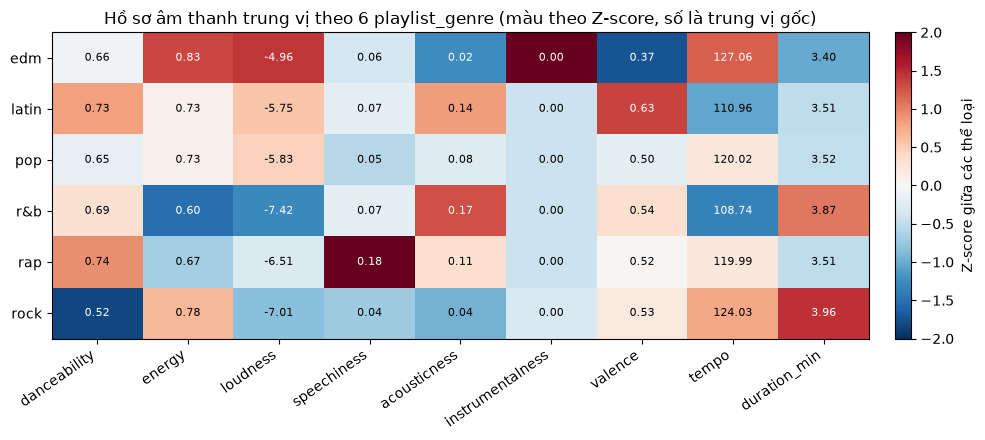

So sánh valence và track_popularity giữa mode = 0 (Minor) và mode = 1 (Major) trên df_tracks:


valence        track_popularity        energy       
        mean median             mean median   mean median
mode                                                     
0       0.51   0.51            38.89  42.00   0.70   0.72
1       0.51   0.51            39.67  43.00   0.70   0.72

In [43]:
audio_profile_cols = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'valence', 'tempo', 'duration_min'
]
genre_profile = df.groupby('playlist_genre', observed=True)[['track_popularity', 'release_year'] + audio_profile_cols].median()
genre_profile['pre_2000_pct (%)'] = df.groupby('playlist_genre', observed=True)['release_year'].apply(lambda s: (s < 2000).mean() * 100)
print('Trung vị các chỉ số theo 6 playlist_genre (trên df):')
display(genre_profile)

# Heatmap chuẩn hóa Z-score theo từng cột để so sánh trực quan đặc trưng nổi bật của từng thể loại
z_profile = (genre_profile[audio_profile_cols] - genre_profile[audio_profile_cols].mean()) / genre_profile[audio_profile_cols].std()
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(z_profile.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(audio_profile_cols)))
ax.set_yticks(range(len(z_profile.index)))
ax.set_xticklabels(audio_profile_cols, rotation=35, ha='right')
ax.set_yticklabels(z_profile.index)
for i in range(len(z_profile.index)):
    for j in range(len(audio_profile_cols)):
        raw_val = genre_profile[audio_profile_cols].iloc[i, j]
        z_val = z_profile.iloc[i, j]
        ax.text(j, i, f'{raw_val:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(z_val) > 1.1 else 'black')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.03, label='Z-score giữa các thể loại')
ax.set_title('Hồ sơ âm thanh trung vị theo 6 playlist_genre (màu theo Z-score, số là trung vị gốc)')
plt.tight_layout()
plt.show()

print('So sánh valence và track_popularity giữa mode = 0 (Minor) và mode = 1 (Major) trên df_tracks:')
display(df_tracks.groupby('mode', observed=True)[['valence', 'track_popularity', 'energy']].agg(['mean', 'median']))

### Độ tương quan giữa số lần bài hát xuất hiện trong playlist / số thể loại bài hát có với `track_popularity`

Độ phổ biến theo số playlist mà bài hát xuất hiện:


,so_bai,pop_median,pop_mean,pop_zero_pct
playlist_group,,,,
1,25538,40.00,37.10,10.14
2,2113,62.00,55.60,1.42
3,481,73.00,68.02,0.00
4+,224,82.00,78.58,0.00


Độ phổ biến giữa bài đơn thể loại và đa thể loại:


,so_bai,pop_median,pop_mean,pop_zero_pct
Đơn thể loại (1 genre),26669,41.00,37.92,9.80
Đa thể loại (>= 2 genres),1687,68.00,61.65,0.41


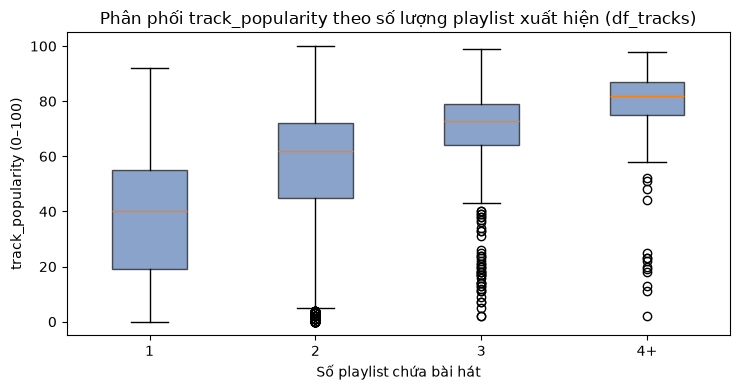

In [44]:
track_exposure = df.groupby('track_id').agg(
    n_playlists=('playlist_id', 'nunique'),
    n_genres=('playlist_genre', 'nunique'),
    track_popularity=('track_popularity', 'first'),
)
track_exposure['playlist_group'] = pd.cut(track_exposure['n_playlists'], bins=[0, 1, 2, 3, 100], labels=['1', '2', '3', '4+'])

exposure_summary = track_exposure.groupby('playlist_group', observed=True).agg(
    so_bai=('track_popularity', 'size'),
    pop_median=('track_popularity', 'median'),
    pop_mean=('track_popularity', 'mean'),
    pop_zero_pct=('track_popularity', lambda s: (s == 0).mean() * 100),
)
print('Độ phổ biến theo số playlist mà bài hát xuất hiện:')
display(exposure_summary)

multi_genre_summary = track_exposure.groupby(track_exposure['n_genres'] >= 2).agg(
    so_bai=('track_popularity', 'size'),
    pop_median=('track_popularity', 'median'),
    pop_mean=('track_popularity', 'mean'),
    pop_zero_pct=('track_popularity', lambda s: (s == 0).mean() * 100),
)
multi_genre_summary.index = ['Đơn thể loại (1 genre)', 'Đa thể loại (>= 2 genres)']
print('Độ phổ biến giữa bài đơn thể loại và đa thể loại:')
display(multi_genre_summary)

fig, ax = plt.subplots(figsize=(7.5, 4))
groups = ['1', '2', '3', '4+']
data_box = [track_exposure.loc[track_exposure['playlist_group'] == g, 'track_popularity'] for g in groups]
ax.boxplot(data_box, tick_labels=groups, patch_artist=True, boxprops=dict(facecolor='#4C72B0', alpha=0.65))
ax.set_title('Phân phối track_popularity theo số lượng playlist xuất hiện (df_tracks)')
ax.set_xlabel('Số playlist chứa bài hát')
ax.set_ylabel('track_popularity (0–100)')
plt.tight_layout()
plt.show()

### Kết luận mục 2.5
- **Tương quan biến số:** Mạnh nhất là `energy`–`loudness` ($r_s = +0.66$, lưu ý đa cộng tuyến cho mô hình tuyến tính), `energy`–`acousticness` ($r_s = -0.50$), `duration_min`–`release_year` ($r_s = -0.45$, bài hát ngắn dần từ trung vị 4,36 phút ở thập niên 1990 xuống 3,15 phút ở 2020) và `danceability`–`valence` ($r_s = +0.33$). Ngược lại, **từng đặc trưng âm thanh đơn lẻ tương quan rất yếu với `track_popularity`** (tất cả $|r_s| \le 0.17$).
- **Bác bỏ giả thuyết *Recency Bias* đơn điệu:** Đường cong `track_popularity` theo thập kỷ có **dạng chữ U**: nhạc thập niên 1960–1980 có trung vị cao (47–56,5) do *survivorship bias* (chỉ các bản kinh điển mới trụ lại trong playlist năm 2020), còn **thập niên 2000 chạm đáy** (trung vị 34,0) với tỷ lệ `popularity == 0` vọt lên **19,60%**.
- **Hồ sơ âm thanh & biến nhiễu:** 6 `playlist_genre` tách biệt khá rõ về âm thanh (Rap có `speechiness` cao; EDM có `energy`/`tempo`/`instrumentalness` cao; Latin/Pop có `danceability`/`valence` cao; Rock có `duration_min` dài). Đáng chú ý, **độ tuổi bài hát lệch cực mạnh giữa các thể loại**: gần nửa số bài `rock` (49,32%, trung vị năm 2000) phát hành trước năm 2000, trong khi `edm` chỉ có 0,31% (trung vị năm 2018) → `release_year` là **biến nhiễu lớn** khi so sánh `track_popularity`, `loudness` hay `duration_min` theo thể loại.
- **Các quan hệ bất ngờ:**
  - Trái với trực giác nhạc lý, điệu Trưởng (`Major`) và điệu Thứ (`Minor`) có **`valence` trung bình và trung vị giống hệt nhau (0,51)**.
  - Bài hát xuất hiện ở càng nhiều playlist thì `track_popularity` tăng vọt (trung vị **40 → 62 → 73 → 82** tương ứng 1, 2, 3, 4+ playlist), và bài đa thể loại cao hơn hẳn đơn thể loại (68 vs 41). Đây là **cảnh báo data leakage quan trọng** nếu xây dựng mô hình dự đoán `track_popularity`.

## 2.6 Summary

### 1. Các phát hiện chính
1. **Cấu trúc đa cấp & giao thoa playlist:** 32.833 dòng chỉ ứng với 28.356 bài hát độc nhất (4.477 dòng lặp `track_id`, trong đó 1.687 bài thuộc ≥ 2 thể loại, mạnh nhất ở trục `pop`–`edm`–`r&b`–`latin`). Mọi thuộc tính cấp bài hát đều nhất quán 100% giữa các dòng trùng.
2. **Phân phối lệch mạnh & đặc thù âm thanh:** Các cột `instrumentalness`, `liveness`, `speechiness`, `acousticness` lệch phải rất mạnh (`skew` 1,59–2,76); `energy` và `loudness` tương quan dương mạnh ($r_s = 0.66$); bài hát có xu hướng ngắn dần và ồn hơn qua các thập kỷ (*Loudness War*).
3. **Độ phổ biến không phụ thuộc tuyến tính vào âm thanh đơn lẻ và có dạng chữ U theo thời gian:** Mọi đặc trưng âm thanh đều có $|r_s| \le 0.17$ với `track_popularity`. Nhạc thập niên 1960–1980 có điểm phổ biến cao hơn thập niên 2000 (trung vị 47–56,5 vs 34,0) do *survivorship bias* kết hợp tỷ lệ `popularity == 0` cao bất thường (19,60%) ở thập niên 2000.
4. **Biến nhiễu mạnh giữa thể loại và năm phát hành:** 6 thể loại khá cân bằng về số lượng (15–18%) nhưng rất khác về độ tuổi (`rock` có 49,32% bài trước năm 2000, còn `edm` chỉ 0,31%).
5. **Độ phủ playlist liên kết cực mạnh với `track_popularity`:** Trung vị độ phổ biến tăng từ 40 (1 playlist) lên 82 (≥ 4 playlist), đồng thời `mode` (Major/Minor) hầu như không tạo khác biệt về sắc thái cảm xúc (`valence` cùng bằng 0,51).

### 2. Các vấn đề chất lượng dữ liệu nghiêm trọng
- **Trùng lặp `track_id` & nhiễu đa nhãn:** 4.477 dòng lặp `track_id`, 1.687 bài mang nhiều `playlist_genre`, và 582 cặp `(track_id, playlist_id)` bị gắn 2 `playlist_subgenre` khác nhau.
- **Dữ liệu NaN và thiếu:** 5 dòng thiếu đồng thời `track_name`, `track_artist`, `track_album_name`; 1.681 bài độc nhất (5,93%) thiếu ngày/tháng phát hành (tập trung ở nhạc cũ trước năm 2000).
- **Giá trị `0` bất thường & cardinality cao:** 2.620 bài độc nhất (9,24%) có `track_popularity == 0`; 1 bài dài 4 giây có `tempo == 0` và `danceability == 0`; `track_artist` có 10.692 giá trị với 60,76% chỉ xuất hiện 1 lần và 7 cặp khác nhau về viết hoa/thường.

### 3. Kế hoạch tiền xử lý (đóng gói vào `src/`)
1. **Chuẩn hóa cột & kiểu dữ liệu:** Trích xuất `release_year` (`int32`) và `duration_min` (`float64`); đổi `playlist_genre`, `playlist_subgenre`, `key`, `mode` sang `category`; loại bỏ `playlist_name` (không định danh duy nhất) và chuỗi ngày gốc `track_album_release_date`.
2. **Làm sạch lỗi rõ ràng:** Loại bỏ 5 dòng `NaN` metadata (khi phân tích cần nghệ sĩ/tên bài hoặc ghép dữ liệu ngoài) và 1 bài lỗi trích xuất `tempo == 0` / `danceability == 0`; giữ nguyên 6 bài `loudness > 0 dB` (dữ liệu thật).
3. **Tách bảng chuẩn theo mục đích phân tích:**
   - `df_playlist` (cấp *bài hát × playlist × subgenre*): dùng cho các câu hỏi liên quan đến cấu trúc playlist hoặc giao thoa thể loại.
   - `df_tracks` (1 dòng / `track_id`): dùng cho phân tích cấp bài hát và mô hình ML. Với 1.687 bài đa thể loại, sẽ nêu rõ quy tắc xử lý theo từng câu hỏi (gán nhãn thể loại xuất hiện nhiều nhất, hoặc loại bỏ khi huấn luyện bài toán phân loại đơn nhãn và kiểm tra độ nhạy).
4. **Kiểm tra độ nhạy (Robustness check – D6):** Giữ `track_popularity == 0` trong phân tích chính và chạy lại sau khi loại nhóm này để kiểm chứng kết luận có bền vững không.